In [4]:
#!/usr/bin/env python3

import os, sys
sys.path.append('../')
import numpy as np
from matplotlib import pyplot as plt
import matplotlib as mpl
from collections import namedtuple
import sys
import glob
import pandas as pd
sys.path.append('../')

try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass
delphesDir = os.path.abspath("../../DelphesLLP")
os.environ['ROOT_INCLUDE_PATH'] = os.path.join(delphesDir,"external")

import ROOT


ROOT.gSystem.Load(os.path.join(delphesDir,"libDelphes.so"))

ROOT.gInterpreter.Declare('#include "classes/SortableObject.h"')
ROOT.gInterpreter.Declare('#include "classes/DelphesClasses.h"')
ROOT.gInterpreter.Declare('#include "external/ExRootAnalysis/ExRootTreeReader.h"')



False

cling::DynamicLibraryManager::loadLibrary(): libpythia8.so: cannot open shared object file: No such file or directory
input_line_60:1:10: fatal error: 'classes/SortableObject.h' file not found
#include "classes/SortableObject.h"
         ^~~~~~~~~~~~~~~~~~~~~~~~~~
input_line_61:1:10: fatal error: 'classes/DelphesClasses.h' file not found
#include "classes/DelphesClasses.h"
         ^~~~~~~~~~~~~~~~~~~~~~~~~~
input_line_62:1:10: fatal error: 'external/ExRootAnalysis/ExRootTreeReader.h' file not found
#include "external/ExRootAnalysis/ExRootTreeReader.h"
         ^~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


In [2]:
def get_labels(df_selected,all_df=[],full_label=False):

    labels = {'mS' : lambda x: r'$m_S$ =' + f' {x:1.2f} [GeV]',
          'm1' : lambda x: r'$m_{\chi_1}$ =' + f' {x:1.2f} [GeV]',
          'dm' : lambda x: r'$\Delta m$ =' + f' {x:1.2f} [GeV]',
          'tau' : lambda x: r'$c \tau$ =' + f' {x*3e8:1.0f} [m]',
        #   'm0' : lambda x: r'$m_{\chi_0}$ =' + f' {x:1.2f} [GeV]',
        #   'm2' : lambda x: r'$m_{\chi_2}$ =' + f' {x:1.2f} [GeV]'          
         }

    model_label = [labels[k](float(df_selected[k].values[0])) for k in labels if k in df_selected.columns]
    if full_label:
        return ', '.join(model_label)
    all_labels = []
    for df in all_df:
        all_labels.append([labels[k](float(df[k].values[0])) for k in labels if k in df.columns])
    labelsDict = {}
    for labelList in all_labels:
        for label in labelList:
            labelsDict.setdefault(label,0)
            labelsDict[label] += 1
    common_labels = [l for l,c in labelsDict.items() if c == len(all_labels)]
    short_label = [l for l in model_label if l not in common_labels]
    short_label = ', '.join(short_label)
    common_label = ', '.join(common_labels)
    return short_label,common_label


def closestDF(dfList, point, relative=True):
    """Return the DataFrame with the parameters closest to point 
    (dict column -> value)."""
    min_dist = float('inf')
    closest_df = None
    for df in dfList:
        row = df.iloc[0]
        cols = list(point.keys())
        target = pd.Series(point)
        diff = row[cols] - target
        if relative:
            diff = diff / target.abs().where(target != 0, 1.0)   # relative difference (absolute if target is 0)
        dist = sum(diff**2)
        if dist < min_dist:
            min_dist = dist
            closest_df = df
    return closest_df   # double brackets keep it a DataFrame


## Read events

In [5]:
processFolders = '../../processFolders/pp2chi1chi2_01j_nosmear_13TeV_new'


runs = ['run_349', 'run_181']

files = []
for f in runs:
    runFolder = os.path.join(processFolders, 'Events', f)
    rootFile = list(glob.glob(os.path.join(runFolder, '*.root')))[0]
    files.append(rootFile)


### Get LLP decay position and time from truth level events (does not include propagation)

In [3]:
rDecaysDict = {}
metDict = {}
dfDict = {}
decayVertex = namedtuple('decayVertex',['x','y','z','t','beta','l','rho'])
for label,file in files.items():
    if not os.path.isfile(file):
        print(f"File {file} not found, skipping")
        continue
    f = ROOT.TFile(file,'read')
    tree = f.Get("Delphes")
    nevts = tree.GetEntries()
    rDecays = []
    metList = []
    for ievt in range(nevts):
        tree.GetEntry(ievt)

        llpDec = {}
        llpBoost = {}
        llps = list(tree.llpParticles)
        for illp,llp in enumerate(llps):
            p = np.array([llp.Px,llp.Py,llp.Pz,llp.E])
            beta = np.linalg.norm(p[:3])/p[3]
            llpBoost[illp] = beta
        
        for d in tree.llpDirectDaughters:
            illp = d.M1
            if illp in llpDec:
                continue
            beta = llpBoost[illp]
            decayVtx = decayVertex(d.X*1e-3,d.Y*1e-3,d.Z*1e-3,d.T,beta,
                                   float(np.linalg.norm([d.X,d.Y,d.Z])*1e-3),
                                   float(np.linalg.norm([d.X,d.Y])*1e-3))
            t_readout = decayVtx.t-decayVtx.l/c_light
            t_readout = t_readout*1e9
            llpDec[illp] = decayVtx._replace(t=t_readout)
        decs = sorted(llpDec.values(), key = lambda d : d[3])
        if len(decs) != 1:
            raise ValueError(f"Event {ievt} has {len(decs)} decays, expected 1")
        rDecays.append(decs[0])
        metList.append(tree.L1METOnTime.At(0).MET)
    f.Close()
    dfDict[label] = pd.DataFrame(rDecays, columns=decayVertex._fields)
    dfDict[label]['met'] = metList
    rDecaysDict[label] = np.array(rDecays,dtype=[(field,'f8') for field in decayVertex._fields])
    metDict[label] = np.array(metList,dtype='f8')

In [4]:
for label,df in dfDict.items():
    print(f"{label}: {len(df)} events")

$\Delta m = 15$ GeV: 26191 events
$\Delta m = 100$ GeV: 25932 events


# Plot decay time

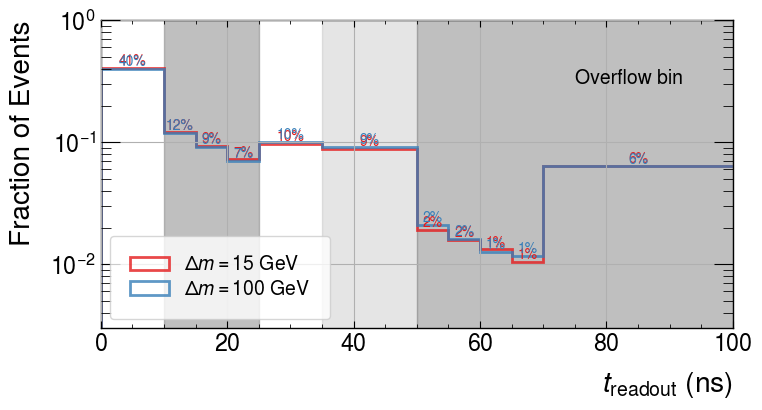

In [5]:
fig = plt.figure(figsize=(8,4))
bins = [0.,10.,15.,20.,25.,35.,50.,55.,60.,65.,70.,10000.]
cmap = mpl.colormaps['Set1']
colors = cmap(list(range(len(dfDict))))
for icurve,label in enumerate(dfDict.keys()):
    df = dfDict[label]
    h,_,patches = plt.hist(df['t'],bins=bins,
             histtype='step',
             weights=[1.0/len(df)]*len(df),
             label=label,linewidth=2,color=colors[icurve],alpha=0.8)
    for i in range(len(bins)-1):
        if h[i] == 0:
            continue
        xpos = 0.5*(bins[i]+min(bins[i+1],100.))
        plt.text(xpos,h[i]*(1.0+0.0*icurve),f"{100*h[i]:.0f}%",ha='center',va='bottom',
                 fontsize=10,color=colors[icurve])
plt.yscale('log')
plt.xlabel(r'$t_{\rm readout}$ (ns)')
plt.ylabel('Fraction of Events')
# plt.vlines(x=[10.,25.,35.],ymin=1e-5,ymax=1,linestyles='dashed',colors='red')
plt.text(75.,0.3,"Overflow bin")
plt.fill_betweenx(y=[1e-5,1],x1=10,x2=25,color='gray',alpha=0.5)
plt.fill_betweenx(y=[1e-5,1],x1=35,x2=50,color='gray',alpha=0.2)
plt.fill_betweenx(y=[1e-5,1],x1=50,x2=100,color='gray',alpha=0.5)
plt.xlim(0.,100)
plt.ylim(3e-3,1)
plt.legend(loc='lower left',framealpha=0.8,frameon=True)
plt.grid()
plt.show()

# Plot decay length

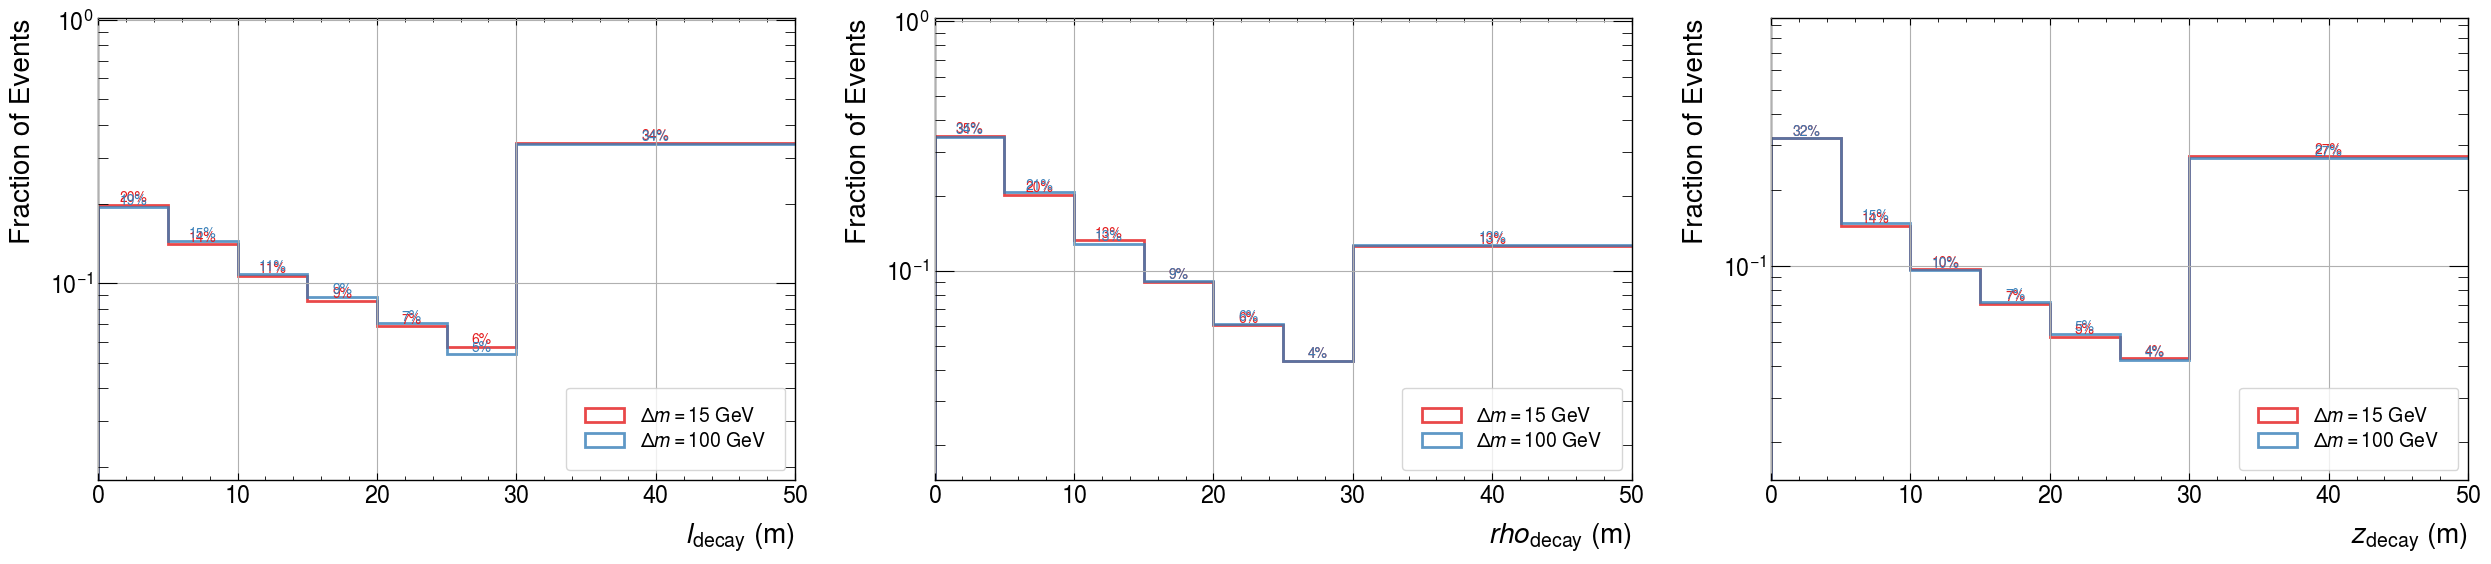

In [6]:
bins = [0.,5.,10.,15.,20.,25.,30.,1000.]
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(10*3, 6*1))

for i,var in enumerate(['l','rho','z']):
    for icurve,label in enumerate(dfDict.keys()):
        df = dfDict[label]
        h,_,patches = axes[i].hist(np.abs(df[var]),bins=bins,
                histtype='step',
                weights=[1.0/len(df)]*len(df),
                label=label,linewidth=2,color=colors[icurve],alpha=0.8)
        for ib in range(len(bins)-1):
            if h[ib] < 0.01:
                continue
            xpos = 0.5*(bins[ib]+min(bins[ib+1],50.))
            axes[i].text(xpos,h[ib]*(1.0+0.0*icurve),f"{100*h[ib]:.0f}%",ha='center',va='bottom',
                    fontsize=10,color=colors[icurve])
    axes[i].set_yscale('log')
    axes[i].set_xlabel(r'$%s_{\rm decay}$ (m)' %var)
    axes[i].set_ylabel('Fraction of Events')
    axes[i].set_xlim(0.,50)
    axes[i].set_ylim(min(h)/3.,max(h)*3.0)
    axes[i].legend(loc='lower right',framealpha=0.8,frameon=True)
    axes[i].grid()
plt.show()

## Define auxiliary functions

In [7]:
@np.vectorize
def in_hcal(z,rho):

    if 4.3 < abs(z) < 5.0 and rho < 3.5:
        return True
    elif 2.0 < rho < 3.5 and abs(z) < 4.3:
        return True
    else:
        return False
@np.vectorize
def in_ms(z,rho):

    if 7.0 < abs(z) < 13.0 and rho < 7.5:
        return True
    elif 3.5 < rho < 7.5 and abs(z) < 7.0:
        return True
    else:
        return False

@np.vectorize
def in_N(t):
    
    if t < 10.0:
        return True
    else:
        return False

@np.vectorize
def in_Np1(t):

    if 25.0 < t < 50.0:
        return True
    else:
        return False

### Split LLPs decaying in N-1 and N and in MS and HCAL

In [8]:
for label,df in dfDict.items():
    df['ontime'] = in_N(df['t'])
    df['delayed'] = in_Np1(df['t'])
    df['in MS'] = in_ms(df['z'],df['rho'])
    df['in HCAL'] = in_hcal(df['z'],df['rho'])
    print(f'{label} : decays in N = {sum(df["ontime"])/len(df):1.4f}, decays in N+1 = {sum(df["delayed"])/len(df):1.4f}')

$\Delta m = 15$ GeV : decays in N = 0.4067, decays in N+1 = 0.1843
$\Delta m = 100$ GeV : decays in N = 0.4016, decays in N+1 = 0.1917


### Count decays in N+1 and MS

In [9]:
for label,df in dfDict.items():
    nMS_delayed = len(df[df['in MS'] & df['delayed']])/sum(df["delayed"])
    print(f'{label} : decays in MS = {nMS_delayed:1.4f}')

print("\nImposing MET > 200")
for label,df in dfDict.items():
    nMS_delayed = len(df[df['in MS'] & df['delayed'] & (df['met'] > 200)])/sum(df["delayed"])
    print(f'{label} : decays in MS = {nMS_delayed:1.4f}')
    


$\Delta m = 15$ GeV : decays in MS = 0.0711
$\Delta m = 100$ GeV : decays in MS = 0.0672

Imposing MET > 200
$\Delta m = 15$ GeV : decays in MS = 0.0075
$\Delta m = 100$ GeV : decays in MS = 0.0030


# Plot decay position

### Plot decays

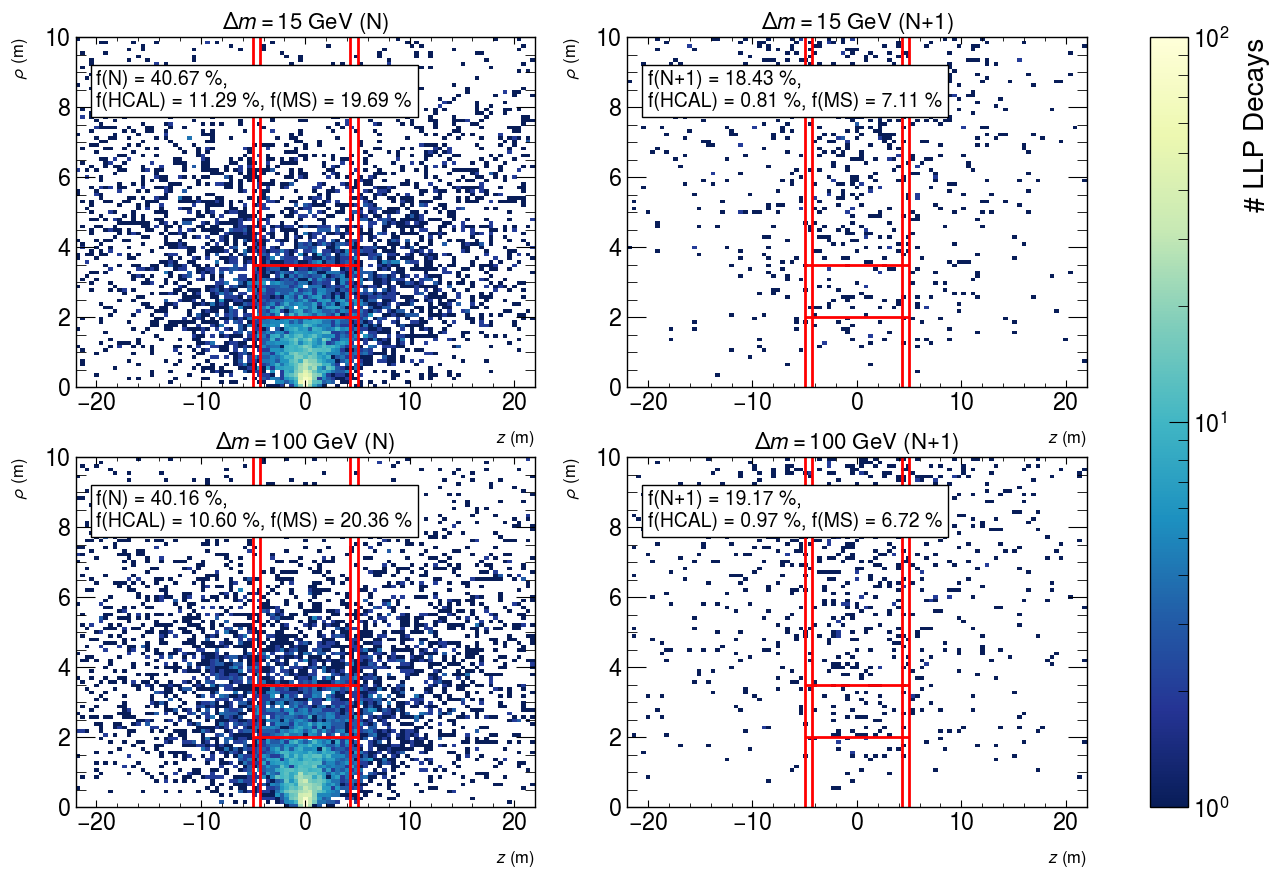

In [10]:


fig, axes = plt.subplots(nrows=len(rDecaysDict), ncols=2, figsize=(8*2, 5*len(rDecaysDict)))

images = []
for j,label in enumerate(dfDict.keys()):
    for i,decayType in enumerate(['ontime','delayed']):
        df = dfDict[label]
        df = df[df[decayType]].copy()
        ax = axes[j,i]
        _,_,_,im = ax.hist2d(df['z'],df['rho'],
            bins=[np.linspace(-22,22,100),np.linspace(0.,10.,100)],
            cmap = mpl.colormaps['YlGnBu_r'], 
            norm = mpl.colors.LogNorm(vmin=1.0,vmax=100.))
        if i == 0:
            ax.set_title(f'{label} (N)',fontsize=16)
        else:
            ax.set_title(f'{label} (N+1)',fontsize=16)
        images.append(im)

        nHcal = sum(df['in HCAL'])
        nHcal = (100.0*nHcal)/len(df)

        nMS = sum(df['in MS'])
        nMS = (100.0*nMS)/len(df)

        n = 100.0*len(df)/len(rDecaysDict[label])
        if i == 0:
            ax.text(-20.,8.,f'f(N) = {n:1.2f} %,\nf(HCAL) = {nHcal:1.2f} %, f(MS) = {nMS:1.2f} %',alpha=1.0,fontsize=14, bbox=dict(facecolor='white', alpha=1.0))
        else:
            ax.text(-20.,8.,f'f(N+1) = {n:1.2f} %,\nf(HCAL) = {nHcal:1.2f} %, f(MS) = {nMS:1.2f} %',alpha=1.0,fontsize=14, bbox=dict(facecolor='white', alpha=1.0))

        ax.vlines(x=[4.3,5.0],ymin=0.,ymax=10.,colors='red')
        ax.vlines(x=[-4.3,-5.0],ymin=0.,ymax=10.,colors='red')
        ax.hlines(y=[2.0,3.5],xmin=-5.0,xmax=5.0,colors='red')
        ax.set_xlabel(r'$z$ (m)',fontsize=12)
        ax.set_ylabel(r'$\rho$ (m)',fontsize=12)

fig.colorbar(images[0], ax=axes.ravel().tolist(), orientation='vertical', label='# LLP Decays')        
plt.show()

### Plot Boost

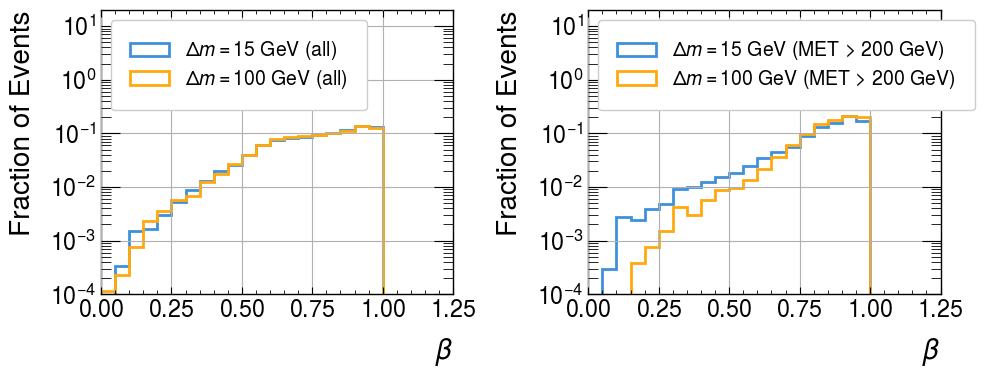

In [32]:

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(5*2, 4))


for label,df in dfDict.items():
    pts = df.copy()
    axes[0].hist(pts['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(pts)]*len(pts),
             label=f'{label} (all)',linewidth=2)
    pts = df[df['met'] > 200.0].copy()
    axes[1].hist(pts['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(pts)]*len(pts),
             label=f'{label} (MET > 200 GeV)',linewidth=2)
for ax in axes:
    ax.set_yscale('log')
    ax.set_xlabel(r'$\beta$')
    ax.set_ylabel('Fraction of Events')
    ax.legend(loc='upper left',framealpha=1.0,frameon=True)
    ax.grid()
    ax.set_ylim(1e-4,20)
plt.tight_layout()
plt.show()

The requirement MET > 200 GeV can not be satisfied by the visible energy deposited by the chi2 decay, therefore it requires ISR. However, the pT from ISR and
the visible chi2 decay (b + b jets) partially cancel, since they approximately recoil against each other.
For large deltaM, the pT(bb) is larger and more ISR is required in order to satisfy the MET cut. As a result the event becomes more boosted and the larger
chi1 boost leads to fewer decays in the MS.

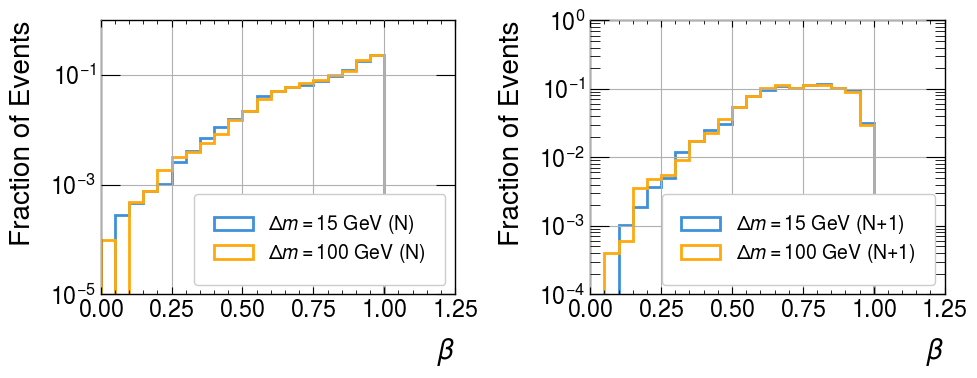

In [14]:

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(5*2, 4))


for label,df in dfDict.items():
    pts = df[df['ontime']].copy()
    axes[0].hist(pts['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(pts)]*len(pts),
             label=f'{label} (N)',linewidth=2)
    pts = df[df['delayed']].copy()
    axes[1].hist(pts['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(pts)]*len(pts),
             label=f'{label} (N+1)',linewidth=2)
for ax in axes:
    ax.set_yscale('log')
    ax.set_xlabel(r'$\beta$')
    ax.set_ylabel('Fraction of Events')
    ax.legend(loc='lower right',framealpha=1.0,frameon=True)
    ax.grid()
plt.tight_layout()
plt.show()

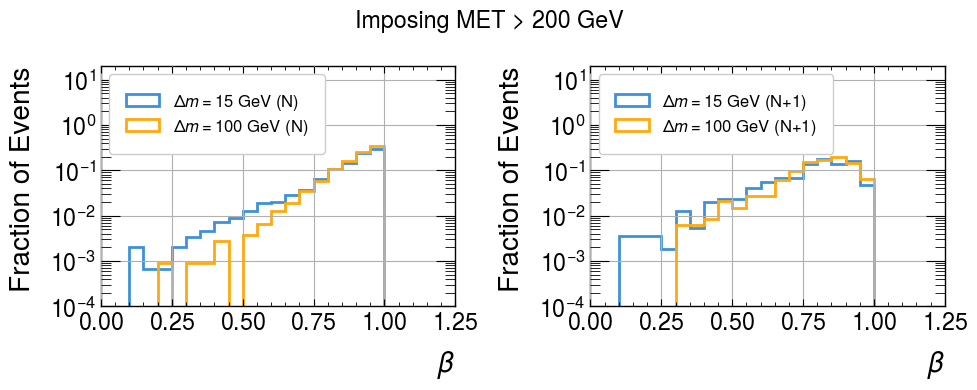

In [20]:

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(5*2, 4))


for label,df in dfDict.items():
    pts = df[df['ontime'] & (df['met'] > 200.0)].copy()
    axes[0].hist(pts['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(pts)]*len(pts),
             label=f'{label} (N)',linewidth=2)
    pts = df[df['delayed'] & (df['met'] > 200.0)].copy()
    axes[1].hist(pts['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(pts)]*len(pts),
             label=f'{label} (N+1)',linewidth=2)
for ax in axes:
    ax.set_yscale('log')
    ax.set_xlabel(r'$\beta$')
    ax.set_ylabel('Fraction of Events')
    ax.legend(loc='upper left',framealpha=1.0,frameon=True,fontsize=12)
    ax.set_ylim(1e-4,20)
    ax.grid()
plt.suptitle("Imposing MET > 200 GeV")
plt.tight_layout()
plt.show()

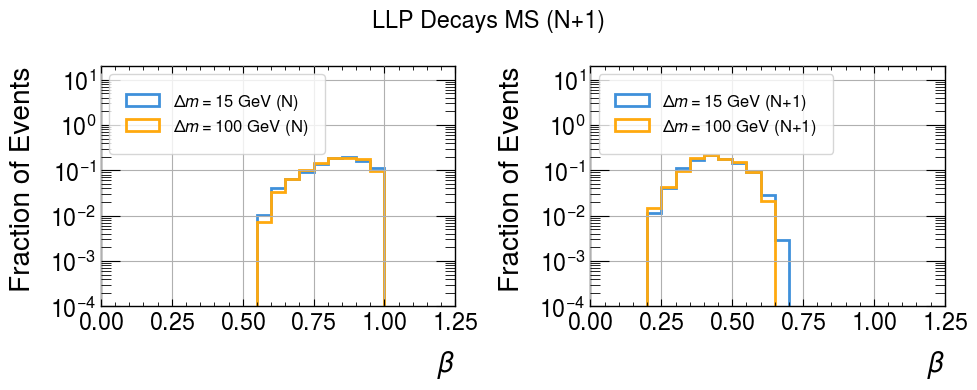

In [27]:

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(5*2, 4))


for label,df in dfDict.items():   
    df_ontime = df[df['in MS'] & df['ontime']].copy()
    axes[0].hist(df_ontime['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(df_ontime)]*len(df_ontime),
             label=f'{label} (N)',linewidth=2)

    def_delayed = df[df['in MS'] & df['delayed']].copy()
    axes[1].hist(def_delayed['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(def_delayed)]*len(def_delayed),
             label=f'{label} (N+1)',linewidth=2)
for ax in axes:
    ax.set_yscale('log')
    ax.set_xlabel(r'$\beta$')
    ax.set_ylabel('Fraction of Events')
    ax.legend(loc='upper left',framealpha=0.8,frameon=True,fontsize=12)
    ax.grid()
    ax.set_ylim(1e-4,20)
plt.suptitle('LLP Decays MS (N+1)')
plt.tight_layout()
plt.show()

# Plot Missing Energy (N)

$\Delta m = 15$ GeV 0.12679928219617426
$\Delta m = 100$ GeV 0.10060928582446398


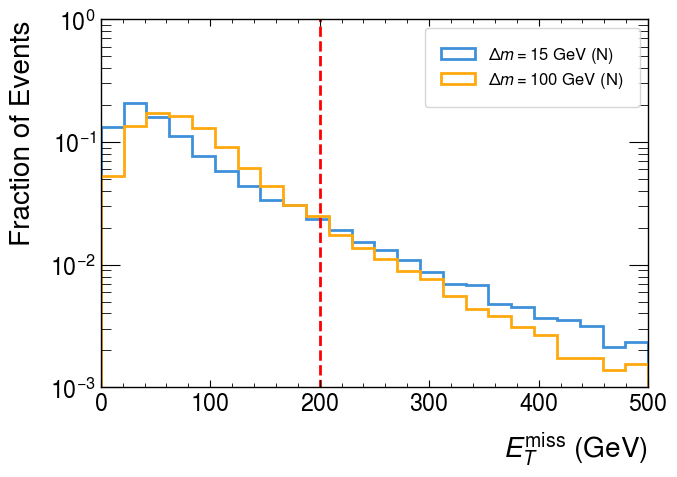

In [29]:

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))

for label,df in dfDict.items():
    axes.hist(df['met'],bins=np.linspace(0.,500.0,25),
             histtype='step',
             weights=[1.0/len(df)]*len(df),
             label=f'{label} (N)',linewidth=2)
    axes.set_yscale('log')
    axes.set_xlabel(r'$E_T^{\rm miss}$ (GeV)')
    axes.set_ylabel('Fraction of Events')
    axes.legend(loc='upper right',framealpha=0.8,frameon=True,fontsize=12)
    axes.grid()
    print(label,len(df[df['met'] > 200.0])/len(df))
axes.vlines(x=200.,ymin=0.,ymax=1.0,color='red',linestyles='dashed',label=r'$E_T^{\rm miss} = 200$ GeV')
plt.tight_layout()
plt.show()